# SE309-50 · Dementia Screening from Tabular Brain-Imaging Features

**Course:** SE309 AI and Data Science for Innovation in Health Science · Fall 2026–27  
**Topic code:** SE309-50 · **Working as:** Group (5 members)  
**Agreed extra feature(s):** Scope for a group of 5 — (1) Core + subject-wise split extension, (2) Longitudinal conversion prediction on OASIS-2, (3) External validation between OASIS-1 and OASIS-2, (4) Model reliance / MMSE ablation & sex/age subgroup audit, (5) Screening model selection, ROC threshold tuning, and prevalence-adjusted precision analysis (Member 5).  
**Repository:** https://github.com/furkanduzgun52/SE309-Brain-Imaging

| Name | Student no. | GitHub username |
|---|---|---|
| Furkan Selami Düzgün | 220201815 | @furkanduzgun52 |
| Burak Emre Başar | 220201068 | @aLpwren |
| Alperen Keskin | 230201094 | *(pending in sheet)* |
| Yaman Balcı | 220201081 | *(pending in sheet)* |
| Fatih Osman Darılmaz | 220201083 | @darilmaz-cmd |

## 1. Problem

Early identification of dementia in memory-clinic triage is challenging because cognitive impairment overlaps with normal ageing and missing a true patient delays support and further testing. This project investigates whether tabular demographic, cognitive (MMSE), and structural MRI volumetric features (`eTIV`, `nWBV`, `ASF`) from the public OASIS cohorts can support dementia screening without using the diagnostic Clinical Dementia Rating (`CDR`) score as an input. The intended users are clinicians or screening coordinators deciding which older adults should be referred for a full specialist dementia work-up, not as a standalone diagnostic tool. In this notebook, we implement the leakage-free data preparation and subject-wise splitting pipeline (Part 1 foundation) and complete **Member 5's screening study**: comparing multiple classifiers via subject-wise stratified 10-fold cross-validation against the ZeroR baseline, selecting a high-sensitivity screening threshold on training data only, analysing positive predictive value (precision) under realistic 10% community prevalence, and evaluating the final model once on a held-out test set.

## 2. Data

- **OASIS-1 (Cross-Sectional):** 436 MRI sessions across 416 unique right-handed subjects aged 18–96 (`oasis_cross-sectional-5708aa0a98d82080.xlsx`). Clinical dementia labels (`CDR`) and cognitive/SES/education fields are available for 235 sessions (ages 33–96), while 201 younger sessions (ages 18–58, including 20 reliability repeats) have `CDR = NaN`.
- **OASIS-2 (Longitudinal):** 373 MRI visits across 150 unique right-handed subjects aged 60–98 (`oasis_longitudinal_demographics-8d83e569fa2e2d30.xlsx`), each imaged across 2–5 visits. Every visit has a `CDR` score (`0.0`, `0.5`, `1.0`, or `2.0`).
- **Source & Terms of Use:** Downloaded from the Open Access Series of Imaging Studies (https://sites.wustl.edu/oasisbrains/) after accepting the **OASIS Data Use Agreement (July 2025 terms)** on 2026-11-21 for non-commercial academic use. Because the OASIS DUA restricts third-party redistribution, each collaborator accepts the terms individually and places the two downloaded Excel files in `data/`.

### Data note

1. **Who is in the data — and who could never have been?** Right-handed volunteers (plus Alzheimer's Disease Research Center patients) in the St. Louis area; OASIS-2 includes adults aged 60–98 with at least two MRI visits. Left-handed individuals, people with MRI contraindications, and severely impaired patients unable to return for longitudinal scans are excluded.
2. **Why was it collected?** Research cohort collected at Washington University's Knight Alzheimer's Disease Research Center (ADRC) to provide open neuroimaging and clinical data on normal ageing and Alzheimer's disease.
3. **When and where?** Published in 2007 (OASIS-1) and 2010 (OASIS-2), collected at Washington University in St. Louis, Missouri, USA.
4. **What exactly is the label, and who decided it?** Clinical Dementia Rating (`CDR`) assigned by ADRC clinicians via structured interviews (`0` = nondemented; `0.5` = very mild, `1` = mild, `2` = moderate dementia). We define the binary screening target as `demented = 1` if `CDR > 0`, else `0`.
5. **What is missing, how much, and by which mechanism?** In OASIS-2, `SES` has 19 missing values (5.1%, across 8 subjects—likely MAR/MNAR when socioeconomic history was unavailable) and `MMSE` has 2 missing values (0.5%). In OASIS-1, `Educ`, `MMSE`, and `CDR` are structurally missing (`201` rows) for participants under 60 by study design, and `SES` is missing in 19 of the 235 older sessions.
6. **Which values are impossible?** No impossible physiological zeros appear in `Age`, `eTIV`, `nWBV`, `ASF`, or `MMSE` (range 4–30 in OASIS-2). `Hand` is constant (`'R'`) for every row in both cohorts, carrying zero predictive information.
7. **When does each column become available (risk of leakage)?** Demographics and MRI measurements are recorded at the visit. **`CDR` defines the outcome** and **`Group`** (`Nondemented`, `Demented`, `Converted`) is a retrospective subject-level label assigned after observing all visits; both cause severe leakage if used as features. Multiple visits of the same subject also leak if split across train and test sets.
8. **Who consented, and to what?** All participants gave informed consent in accordance with Washington University Human Studies Committee guidelines for de-identified data sharing; the user accepted the OASIS Data Use Agreement on 2026-11-21.

## 3. Setup

Import core scientific libraries, fix the random seed (`SEED = 42`), configure figure output, and load both OASIS tabular datasets from `data/`.

In [1]:
import glob
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedGroupKFold, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, recall_score, precision_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, make_scorer
)

SEED = 42
np.random.seed(SEED)

# Resolve repository root whether notebook is executed from repo root or notebooks/
BASE_DIR = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.path.abspath(".")
DATA_DIR = os.path.join(BASE_DIR, "data")
IMG_DIR = os.path.join(BASE_DIR, "images")
os.makedirs(IMG_DIR, exist_ok=True)

print("BASE_DIR:", BASE_DIR)

BASE_DIR: C:\Users\Administrator\.gemini\antigravity\scratch\SE309-50-Dementia


In [2]:
# Load OASIS-1 and OASIS-2 tabular Excel files from data/ (with Colab upload fallback)
o1_files = sorted(glob.glob(os.path.join(DATA_DIR, "oasis_cross-sectional*.xlsx")))
o2_files = sorted(glob.glob(os.path.join(DATA_DIR, "oasis_longitudinal*.xlsx")))

if len(o1_files) == 0 or len(o2_files) == 0:
    try:
        from google.colab import files
        print("OASIS .xlsx files not found in data/. Please upload both OASIS-1 and OASIS-2 Excel files (per OASIS DUA):")
        os.makedirs(DATA_DIR, exist_ok=True)
        uploaded = files.upload()
        for fname, content in uploaded.items():
            with open(os.path.join(DATA_DIR, fname), "wb") as f:
                f.write(content)
        o1_files = sorted(glob.glob(os.path.join(DATA_DIR, "oasis_cross-sectional*.xlsx")))
        o2_files = sorted(glob.glob(os.path.join(DATA_DIR, "oasis_longitudinal*.xlsx")))
    except ImportError:
        pass

assert len(o1_files) == 1 and len(o2_files) == 1, (
    f"Expected 1 OASIS-1 and 1 OASIS-2 xlsx in {DATA_DIR}. "
    "Accept OASIS DUA at https://sites.wustl.edu/oasisbrains/ and place both files in data/."
)

oasis1 = pd.read_excel(o1_files[0])
oasis2 = pd.read_excel(o2_files[0])

print(f"OASIS-1 shape: {oasis1.shape} | unique subjects (ID prefix): {oasis1['ID'].str.slice(0, 9).nunique()}")
print(f"OASIS-2 shape: {oasis2.shape} | unique subjects: {oasis2['Subject ID'].nunique()}")
display(oasis2.head(5))

OASIS-1 shape: (436, 12) | unique subjects (ID prefix): 416
OASIS-2 shape: (373, 15) | unique subjects: 150


,Subject ID,MRI ID,Group,Visit,MR Delay,M/F,Hand,Age,EDUC,SES,MMSE,CDR,eTIV,nWBV,ASF
0,OAS2_0001,OAS2_0001_MR1,Nondemented,1,0,M,R,87,14,2.0,27.0,0.0,1986.550000,0.696106,0.883440
1,OAS2_0001,OAS2_0001_MR2,Nondemented,2,457,M,R,88,14,2.0,30.0,0.0,2004.479526,0.681062,0.875539
2,OAS2_0002,OAS2_0002_MR1,Demented,1,0,M,R,75,12,NaN,23.0,0.5,1678.290000,0.736336,1.045710
3,OAS2_0002,OAS2_0002_MR2,Demented,2,560,M,R,76,12,NaN,28.0,0.5,1737.620000,0.713402,1.010000
4,OAS2_0002,OAS2_0002_MR3,Demented,3,1895,M,R,80,12,NaN,22.0,0.5,1697.911134,0.701236,1.033623


## 4. Exploration

We inspect five-number summaries, missing counts, class balance (`CDR > 0`), and feature distributions by dementia status on OASIS-2 (the primary longitudinal cohort with `SES` and `MMSE` missingness and repeated subject visits), alongside summary statistics for OASIS-1.

In [3]:
# Missing values and summary statistics
print("=== OASIS-2 Missing Values ===")
display(oasis2.isna().sum().to_frame("missing_count"))

print("=== OASIS-2 Numeric Five-Number Summaries ===")
num_summary_cols = ["Age", "EDUC", "SES", "MMSE", "CDR", "eTIV", "nWBV", "ASF"]
display(oasis2[num_summary_cols].describe().round(3))

print("=== OASIS-1 Labeled Subset (CDR not null) Missing Values ===")
oasis1_labeled = oasis1[oasis1["CDR"].notna()].copy()
print(f"OASIS-1 labeled rows: {len(oasis1_labeled)} (of {len(oasis1)} total)")
display(oasis1_labeled.isna().sum().to_frame("missing_count"))

=== OASIS-2 Missing Values ===


,missing_count
Subject ID,0
MRI ID,0
Group,0
Visit,0
MR Delay,0
M/F,0
Hand,0
Age,0
EDUC,0
SES,19


=== OASIS-2 Numeric Five-Number Summaries ===


,Age,EDUC,SES,MMSE,CDR,eTIV,nWBV,ASF
count,373.000,373.000,354.000,371.000,373.000,373.000,373.000,373.000
mean,77.013,14.598,2.460,27.342,0.291,1488.122,0.730,1.195
std,7.641,2.876,1.134,3.683,0.375,176.136,0.037,0.138
min,60.000,6.000,1.000,4.000,0.000,1105.652,0.644,0.876
25%,71.000,12.000,2.000,27.000,0.000,1357.330,0.700,1.099
50%,77.000,15.000,2.000,29.000,0.000,1470.041,0.729,1.194
75%,82.000,16.000,3.000,30.000,0.500,1596.937,0.756,1.293
max,98.000,23.000,5.000,30.000,2.000,2004.480,0.837,1.587


=== OASIS-1 Labeled Subset (CDR not null) Missing Values ===
OASIS-1 labeled rows: 235 (of 436 total)


,missing_count
ID,0
M/F,0
Hand,0
Age,0
Educ,0
SES,19
MMSE,0
CDR,0
eTIV,0
nWBV,0


In [4]:
# Define binary screening target from CDR: demented = 1 if CDR > 0 else 0
oasis2["demented"] = (oasis2["CDR"] > 0).astype(int)

print("OASIS-2 visit-level CDR distribution:")
print(oasis2["CDR"].value_counts().sort_index())
print("\nOASIS-2 visit-level binary target (0 = nondemented, 1 = demented):")
print(oasis2["demented"].value_counts())
print(f"Visit-level prevalence: {oasis2['demented'].mean():.4f} ({oasis2['demented'].sum()}/{len(oasis2)})")
print("\nVisits per subject:")
print(oasis2.groupby("Subject ID").size().value_counts().sort_index())

OASIS-2 visit-level CDR distribution:
CDR
0.0    206
0.5    123
1.0     41
2.0      3
Name: count, dtype: int64

OASIS-2 visit-level binary target (0 = nondemented, 1 = demented):
demented
0    206
1    167
Name: count, dtype: int64
Visit-level prevalence: 0.4477 (167/373)

Visits per subject:
2    94
3    43
4     9
5     4
Name: count, dtype: int64


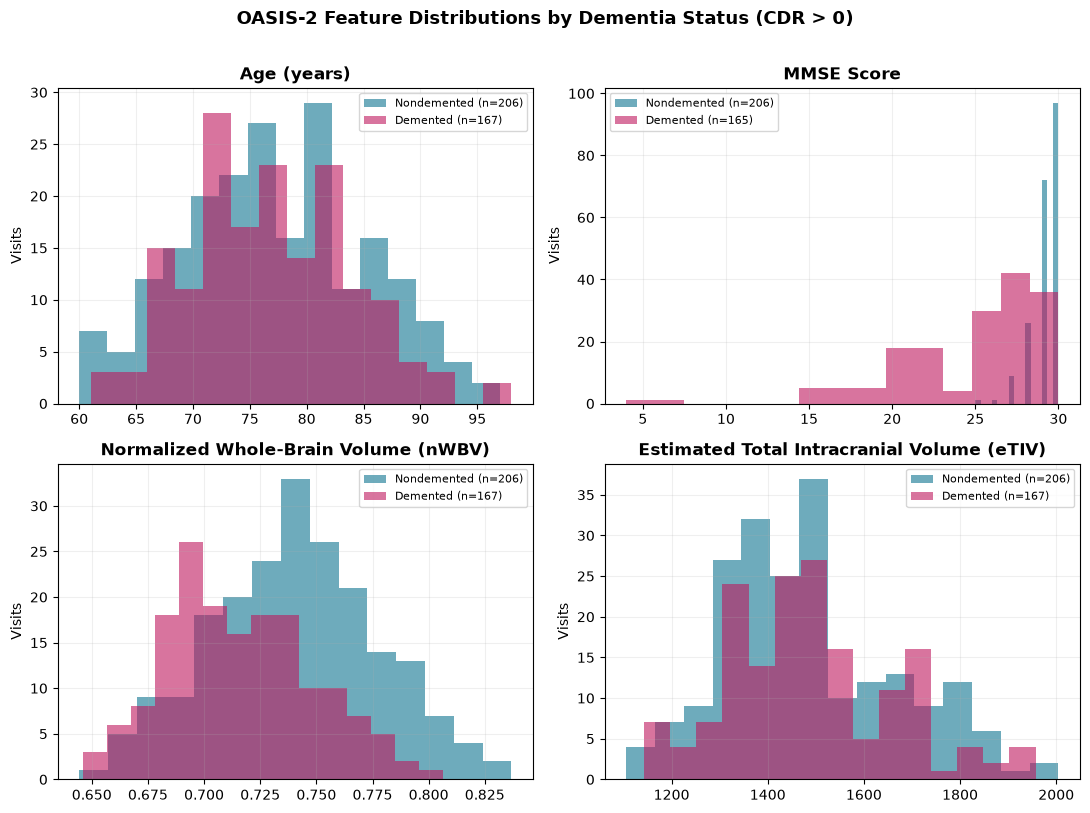

In [5]:
# Plot class-separated distributions for key features and missingness overview
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
plot_cols = [("Age", "Age (years)"), ("MMSE", "MMSE Score"), ("nWBV", "Normalized Whole-Brain Volume (nWBV)"), ("eTIV", "Estimated Total Intracranial Volume (eTIV)")]

for ax, (col, title) in zip(axes.ravel(), plot_cols):
    g0 = oasis2.loc[oasis2["demented"] == 0, col].dropna()
    g1 = oasis2.loc[oasis2["demented"] == 1, col].dropna()
    ax.hist(g0, bins=15, alpha=0.6, label=f"Nondemented (n={len(g0)})", color="#0E7490")
    ax.hist(g1, bins=15, alpha=0.6, label=f"Demented (n={len(g1)})", color="#BE185D")
    ax.set_title(title, fontweight="bold")
    ax.set_ylabel("Visits")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.2)

plt.suptitle("OASIS-2 Feature Distributions by Dementia Status (CDR > 0)", fontsize=13, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig(os.path.join(IMG_DIR, "eda_distributions.png"), dpi=150, bbox_inches="tight")
plt.show()

**Exploration commentary:**  
- **MMSE** shows strong separation: nondemented visits cluster tightly near `28–30`, whereas demented visits spread down to `4–28` with a clear left skew.  
- **nWBV** is lower on average among demented visits (atrophy), while **eTIV** overlaps substantially across classes (reflecting head size, which correlates strongly with sex).  
- **Missingness:** Only `SES` (`19` visits, `5.1%`) and `MMSE` (`2` visits, `0.5%`) have missing values in OASIS-2. `Hand` is `'R'` for all 373 rows and is dropped as a constant feature.

## 5. Preparation

Following **Part 1 (Core + Extension)** and the **Week 4 split-first rule**:
1. **Leakage check:** `CDR` defines the outcome (`demented = 1` if `CDR > 0`) and `Group` encodes retrospective longitudinal conversion across visits. Both `CDR` and `Group`, along with identifiers (`Subject ID`, `MRI ID`, `Visit`, `MR Delay`) and constant `Hand`, are strictly excluded from the input feature list.
2. **Subject-wise train/test split (Extension):** We split at the **subject level** (`150` unique subjects → `75%` = `112` training subjects / `279` visits; `25%` = `38` held-out test subjects / `94` visits), stratified by whether a subject ever has `CDR > 0`. No subject appears in both sets.
3. **Missing-value handling:** We do **not** drop incomplete rows (complete-case analysis would discard 19 visits / ~5% of data, risking selection bias). Instead, we impute `SES` and `MMSE` with the **training-set median** inside a scikit-learn `Pipeline` (median is robust to skewed `MMSE` and ordinal `SES` 1–5; fitting inside the pipeline ensures zero leakage from test rows or CV validation folds). We intentionally avoid adding binary missingness indicators because `MMSE` has only 2 missing rows and near-zero-variance binary indicators distort `GaussianNB`.
4. **Encoding & scaling:** `M/F` is binary-encoded (`0/1`). Numeric features are z-score standardized (`StandardScaler`) inside the pipeline for Logistic Regression and Naive Bayes (while Decision Tree and Random Forest are scale-invariant).

In [6]:
# 1. Explicit Leakage Check & Feature Selection
LEAKY_OR_ID_COLS = ["Subject ID", "MRI ID", "Group", "Visit", "MR Delay", "Hand", "CDR", "demented"]
num_cols = ["Age", "EDUC", "SES", "MMSE", "eTIV", "nWBV", "ASF"]
cat_cols = ["M/F"]
features = num_cols + cat_cols

assert "CDR" not in features, "LEAKAGE ERROR: CDR must never be an input feature!"
assert "Group" not in features, "LEAKAGE ERROR: Group encodes future conversion/outcome!"

# 2. Subject-wise Stratified Train / Held-out Test Split (75% / 25% of subjects)
subject_table = (
    oasis2.sort_values("Visit")
    .groupby("Subject ID", as_index=False)
    .agg(ever_demented=("demented", "max"), n_visits=("Visit", "count"))
)

train_subj, test_subj = train_test_split(
    subject_table["Subject ID"],
    test_size=0.25,
    stratify=subject_table["ever_demented"],
    random_state=SEED,
)

train_df = oasis2[oasis2["Subject ID"].isin(train_subj)].copy()
test_df = oasis2[oasis2["Subject ID"].isin(test_subj)].copy()

# Verify zero subject overlap
overlap = set(train_df["Subject ID"]) & set(test_df["Subject ID"])
assert len(overlap) == 0, f"Subject leakage detected: {overlap}"

X_train, y_train, groups_train = train_df[features], train_df["demented"], train_df["Subject ID"]
X_test, y_test = test_df[features], test_df["demented"]

print(f"Train set: {len(train_df)} visits across {train_df['Subject ID'].nunique()} subjects | Demented rate: {y_train.mean():.3f}")
print(f"Test  set: {len(test_df)} visits across {test_df['Subject ID'].nunique()} subjects | Demented rate: {y_test.mean():.3f}")
print(f"Subject overlap between train and test: {len(overlap)}")

Train set: 279 visits across 112 subjects | Demented rate: 0.455
Test  set: 94 visits across 38 subjects | Demented rate: 0.426
Subject overlap between train and test: 0


In [7]:
# 3. Leakage-free Preprocessing Pipelines (fit only inside training folds / training set)
prep_scaled = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), num_cols),
    ("cat", OneHotEncoder(drop="if_binary", handle_unknown="ignore"), cat_cols),
])

prep_tree = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), num_cols),
    ("cat", OneHotEncoder(drop="if_binary", handle_unknown="ignore"), cat_cols),
])

# Inspect training-only imputation medians (for reporting transparency)
train_medians = X_train[num_cols].median()
print("Training-only medians (learned without touching test set):")
print(train_medians.round(3))

Training-only medians (learned without touching test set):
Age       77.000
EDUC      14.000
SES        2.000
MMSE      29.000
eTIV    1470.873
nWBV       0.731
ASF        1.193
dtype: float64


## 6. Methods

### Part 1 Core Models & Subject-Wise Cross-Validation
To keep both training and validation completely free of subject-level leakage, we evaluate models on the **training set only** using **10-fold `StratifiedGroupKFold`** grouped by `Subject ID` (`n_splits=10, shuffle=True, random_state=SEED`). Every visit of a subject stays in the same fold, and class proportions remain balanced across folds.

### Member 5: Choosing a Model and a Threshold for Screening
Led by **Fatih Osman Darılmaz (`@darilmaz-cmd`)**:
1. We compare four classifiers alongside the **ZeroR (`DummyClassifier`)** baseline using identical Part 1 preparation inside scikit-learn pipelines:
   - **ZeroR (Majority Class Baseline):** Always predicts `0` (nondemented).
   - **Decision Tree (`max_depth=3`):** Pruned tree for interpretability and overfitting control.
   - **Gaussian Naive Bayes (`GaussianNB`):** Probabilistic classifier assuming conditional independence of standardized features.
   - **Logistic Regression (`max_iter=1000`):** Linear log-odds risk model with standardized inputs.
   - **Random Forest (`n_estimators=100`):** Ensemble benchmark (also used to illustrate why ungrouped `StratifiedKFold` inflates performance when multiple visits of the same subject leak across folds).
2. We compute **Accuracy, Sensitivity (Recall), Specificity, Precision, F1, and ROC AUC** from out-of-fold cross-validation predictions on the training set.
3. We plot the ROC curves on training CV probabilities, select the best model, and choose a **memory-clinic screening decision threshold** on **training data only** (where missing a demented patient — False Negative — is the most serious error).

In [8]:
# Define models using identical Part 1 preparation
classifiers = [
    ("ZeroR (Baseline)", Pipeline([("prep", prep_tree), ("clf", DummyClassifier(strategy="most_frequent"))])),
    ("Decision Tree (depth=3)", Pipeline([("prep", prep_tree), ("clf", DecisionTreeClassifier(max_depth=3, random_state=SEED))])),
    ("Naive Bayes (GaussianNB)", Pipeline([("prep", prep_scaled), ("clf", GaussianNB())])),
    ("Logistic Regression", Pipeline([("prep", prep_scaled), ("clf", LogisticRegression(max_iter=1000, random_state=SEED))])),
    ("Random Forest (100 trees)", Pipeline([("prep", prep_tree), ("clf", RandomForestClassifier(n_estimators=100, random_state=SEED))])),
]

cv_subject = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=SEED)

cv_rows = []
cv_probas = {}

for name, pipe in classifiers:
    oof_pred = cross_val_predict(pipe, X_train, y_train, cv=cv_subject, groups=groups_train)
    if name == "ZeroR (Baseline)":
        oof_prob = np.zeros(len(y_train))
        auc = 0.500
    else:
        oof_prob = cross_val_predict(pipe, X_train, y_train, cv=cv_subject, groups=groups_train, method="predict_proba")[:, 1]
        auc = roc_auc_score(y_train, oof_prob)
    cv_probas[name] = oof_prob

    cv_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_train, oof_pred),
        "Sensitivity": recall_score(y_train, oof_pred, pos_label=1),
        "Specificity": recall_score(y_train, oof_pred, pos_label=0),
        "Precision": precision_score(y_train, oof_pred, zero_division=0),
        "F1": f1_score(y_train, oof_pred, zero_division=0),
        "ROC AUC": auc,
    })

cv_table = pd.DataFrame(cv_rows).set_index("Model").round(3)
print("=== 10-Fold Subject-Wise CV (StratifiedGroupKFold) on Training Data (n=279 visits, 112 subjects) ===")
display(cv_table)

=== 10-Fold Subject-Wise CV (StratifiedGroupKFold) on Training Data (n=279 visits, 112 subjects) ===


,Accuracy,Sensitivity,Specificity,Precision,F1,ROC AUC
Model,,,,,,
ZeroR (Baseline),0.545,0.000,1.000,0.000,0.000,0.500
Decision Tree (depth=3),0.767,0.701,0.822,0.767,0.733,0.766
Naive Bayes (GaussianNB),0.796,0.661,0.908,0.857,0.747,0.858
Logistic Regression,0.828,0.756,0.888,0.850,0.800,0.908
Random Forest (100 trees),0.778,0.740,0.809,0.764,0.752,0.852


In [9]:
# Leakage illustration: compare against naive ungrouped StratifiedKFold
cv_ungrouped = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)
leak_rows = []
for name, pipe in classifiers[1:]:
    prob_grp = cv_probas[name]
    prob_raw = cross_val_predict(pipe, X_train, y_train, cv=cv_ungrouped, method="predict_proba")[:, 1]
    leak_rows.append({
        "Model": name,
        "Subject-wise CV AUC": round(roc_auc_score(y_train, prob_grp), 3),
        "Ungrouped CV AUC (Leaky)": round(roc_auc_score(y_train, prob_raw), 3),
        "Inflated Gap": round(roc_auc_score(y_train, prob_raw) - roc_auc_score(y_train, prob_grp), 3),
    })
display(pd.DataFrame(leak_rows).set_index("Model"))

,Subject-wise CV AUC,Ungrouped CV AUC (Leaky),Inflated Gap
Model,,,
Decision Tree (depth=3),0.766,0.810,0.044
Naive Bayes (GaussianNB),0.858,0.872,0.014
Logistic Regression,0.908,0.923,0.015
Random Forest (100 trees),0.852,0.940,0.087


## 7. Results

### 7.1 ROC Curve & Screening Threshold Selection (Training Data Only)
**Logistic Regression** achieves the highest 10-fold subject-wise CV **ROC AUC (`0.908`)**, **Accuracy (`0.828`)**, **Sensitivity (`0.756`)**, and **F1 (`0.800`)**, outperforming Naive Bayes (`AUC 0.858`), Random Forest (`AUC 0.852`), Decision Tree (`AUC 0.766`), and ZeroR (`Acc 0.545, Sens 0.000`).

At the default threshold `t = 0.50`, Logistic Regression misses `31` of `127` demented training visits (`Sensitivity = 0.756`). In a **memory-clinic screening** setting, missing a demented patient (`FN`) is far more serious than flagging a healthy person (`FP`) for a confirmatory cognitive/clinical exam. Following Week 7's cost-based threshold rule (`t = C_FP / (C_FP + C_FN)`):
- Judging a missed dementia case as **3× as costly** as a false alarm gives **`t = 1 / (1 + 3) = 0.25`**.
- Checking the training CV ROC curve confirms that **`t = 0.25`** raises training CV Sensitivity from `0.756` to **`0.913`** (cutting missed cases from `31` to `11`), while keeping Specificity at **`0.658`** (going lower to `t = 0.20` would drop Specificity sharply to `0.572` for only 6 fewer misses).

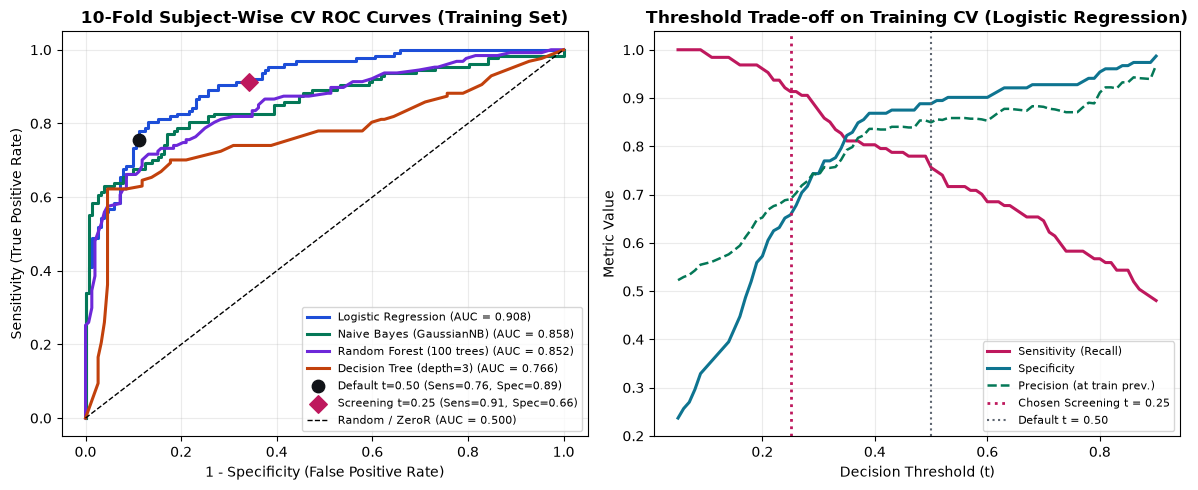

In [10]:
# Plot Training CV ROC Curves and mark the chosen screening threshold (t = 0.25)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

colors = {
    "Logistic Regression": "#1D4ED8",
    "Naive Bayes (GaussianNB)": "#047857",
    "Random Forest (100 trees)": "#6D28D9",
    "Decision Tree (depth=3)": "#C2410C",
}

for name, color in colors.items():
    fpr, tpr, _ = roc_curve(y_train, cv_probas[name])
    auc_val = roc_auc_score(y_train, cv_probas[name])
    ax1.plot(fpr, tpr, lw=2.2, color=color, label=f"{name} (AUC = {auc_val:.3f})")

# Mark t=0.50 and t=0.25 on Logistic Regression CV curve
lr_oof = cv_probas["Logistic Regression"]
for t_val, marker, mcolor, lbl in [(0.50, "o", "#111318", "Default t=0.50"), (0.25, "D", "#BE185D", "Screening t=0.25")]:
    pred_t = (lr_oof >= t_val).astype(int)
    tpr_t = recall_score(y_train, pred_t, pos_label=1)
    fpr_t = 1.0 - recall_score(y_train, pred_t, pos_label=0)
    ax1.scatter([fpr_t], [tpr_t], s=80, color=mcolor, marker=marker, zorder=5, label=f"{lbl} (Sens={tpr_t:.2f}, Spec={1-fpr_t:.2f})")

ax1.plot([0, 1], [0, 1], "k--", lw=1, label="Random / ZeroR (AUC = 0.500)")
ax1.set_xlabel("1 - Specificity (False Positive Rate)")
ax1.set_ylabel("Sensitivity (True Positive Rate)")
ax1.set_title("10-Fold Subject-Wise CV ROC Curves (Training Set)", fontweight="bold")
ax1.legend(loc="lower right", fontsize=8)
ax1.grid(alpha=0.25)

# Threshold trade-off curve for Logistic Regression on training CV
thresholds = np.linspace(0.05, 0.90, 86)
sens_list, spec_list, prec_list = [], [], []
for t in thresholds:
    p_t = (lr_oof >= t).astype(int)
    sens_list.append(recall_score(y_train, p_t, pos_label=1))
    spec_list.append(recall_score(y_train, p_t, pos_label=0))
    prec_list.append(precision_score(y_train, p_t, zero_division=0))

ax2.plot(thresholds, sens_list, color="#BE185D", lw=2.2, label="Sensitivity (Recall)")
ax2.plot(thresholds, spec_list, color="#0E7490", lw=2.2, label="Specificity")
ax2.plot(thresholds, prec_list, color="#047857", lw=1.8, linestyle="--", label="Precision (at train prev.)")
ax2.axvline(0.25, color="#BE185D", linestyle=":", lw=2, label="Chosen Screening t = 0.25")
ax2.axvline(0.50, color="#5D6570", linestyle=":", lw=1.5, label="Default t = 0.50")
ax2.set_xlabel("Decision Threshold (t)")
ax2.set_ylabel("Metric Value")
ax2.set_title("Threshold Trade-off on Training CV (Logistic Regression)", fontweight="bold")
ax2.legend(loc="best", fontsize=8)
ax2.grid(alpha=0.25)

plt.tight_layout()
plt.savefig(os.path.join(IMG_DIR, "roc_threshold_cv.png"), dpi=150, bbox_inches="tight")
plt.show()

In [11]:
# Print detailed threshold table on training CV for Logistic Regression
thresh_rows = []
for t in [0.50, 0.40, 0.35, 0.30, 0.25, 0.20, 0.15]:
    p_t = (lr_oof >= t).astype(int)
    fn = int(((y_train == 1) & (p_t == 0)).sum())
    fp = int(((y_train == 0) & (p_t == 1)).sum())
    thresh_rows.append({
        "Threshold": t,
        "Accuracy": round(accuracy_score(y_train, p_t), 3),
        "Sensitivity": round(recall_score(y_train, p_t, pos_label=1), 3),
        "Specificity": round(recall_score(y_train, p_t, pos_label=0), 3),
        "Precision": round(precision_score(y_train, p_t), 3),
        "F1": round(f1_score(y_train, p_t), 3),
        "FN (Missed)": fn,
        "FP (False Alarm)": fp,
        "Cost (3*FN + FP)": 3 * fn + fp,
    })

display(pd.DataFrame(thresh_rows).set_index("Threshold"))

,Accuracy,Sensitivity,Specificity,Precision,F1,FN (Missed),FP (False Alarm),Cost (3*FN + FP)
Threshold,,,,,,,,
0.50,0.828,0.756,0.888,0.850,0.800,31,17,110
0.40,0.839,0.803,0.868,0.836,0.819,25,20,95
0.35,0.817,0.811,0.822,0.792,0.802,24,27,99
0.30,0.803,0.874,0.743,0.740,0.801,16,39,87
0.25,0.774,0.913,0.658,0.690,0.786,11,52,85
0.20,0.749,0.961,0.572,0.652,0.777,5,65,80
0.15,0.674,0.976,0.421,0.585,0.732,3,88,97


### 7.2 Precision at Two Prevalences (Step-by-Step)
Using our selected model's training 10-fold CV operating characteristics at `t = 0.25` (**Sensitivity = 0.913**, **Specificity = 0.658**), we apply Bayes' theorem / 1,000-patient counts (Week 5, Slide 2.4) at:
1. **OASIS-2 dataset prevalence:** `167 / 373 = 44.77%`
2. **General older population screening prevalence:** `10.0%`

In [12]:
# Step-by-step prevalence calculation (1,000-person cohort, Week 5 Slide 2.4 method)
sens_cv = recall_score(y_train, (lr_oof >= 0.25).astype(int), pos_label=1)
spec_cv = recall_score(y_train, (lr_oof >= 0.25).astype(int), pos_label=0)
prev_oasis2 = oasis2["demented"].mean()
prev_pop = 0.10

def precision_step_by_step(prev, sens, spec, N=1000):
    demented = N * prev
    healthy = N * (1 - prev)
    tp = demented * sens
    fn = demented - tp
    fp = healthy * (1 - spec)
    tn = healthy - fp
    ppv = tp / (tp + fp)
    return {
        "Prevalence": f"{prev*100:.2f}%",
        "Demented (per 1000)": round(demented, 1),
        "Healthy (per 1000)": round(healthy, 1),
        "TP = Demented * Sens": round(tp, 1),
        "FP = Healthy * (1 - Spec)": round(fp, 1),
        "Total Flagged (TP + FP)": round(tp + fp, 1),
        "Precision = TP / (TP + FP)": f"{ppv*100:.1f}%",
    }

prev_df = pd.DataFrame([
    precision_step_by_step(prev_oasis2, sens_cv, spec_cv),
    precision_step_by_step(prev_pop, sens_cv, spec_cv),
])
print(f"Model operating point (Training CV, t=0.25): Sensitivity = {sens_cv:.3f}, Specificity = {spec_cv:.3f}")
display(prev_df)

Model operating point (Training CV, t=0.25): Sensitivity = 0.913, Specificity = 0.658


,Prevalence,Demented (per 1000),Healthy (per 1000),TP = Demented * Sens,FP = Healthy * (1 - Spec),Total Flagged (TP + FP),Precision = TP / (TP + FP)
0,44.77%,447.7,552.3,408.9,188.9,597.9,68.4%
1,10.00%,100.0,900.0,91.3,307.9,399.2,22.9%


**What the prevalence difference means for real use:**  
Although Sensitivity (`91.3%`) and Specificity (`65.8%`) are identical properties of the model, **Precision drops from `~68.4%` in the OASIS-2 cohort (`44.8%` prevalence) to `~22.9%` in a general older population (`10%` prevalence)**. Out of 1,000 older adults screened in the community, `~399` would be flagged positive, of whom `~308` (`77.1%` of all flags!) would be false alarms. In real clinical deployment, this model could **only** serve as an initial triage step followed by a confirmatory clinical/neuropsychological exam — never as a standalone diagnosis, because mass screening would create severe alarm fatigue and patient anxiety.

### 7.3 Final One-Time Held-Out Test Evaluation (`n = 94` visits, `38` unseen subjects)
Having fixed the model (**Logistic Regression**) and screening threshold (**`t = 0.25`**) strictly on the training data, we now fit the pipeline on the full training set (`279` visits, `112` subjects) and evaluate **once** on the locked held-out test set (`94` visits, `38` unseen subjects).

In [13]:
# Fit final model on full training set and evaluate ONCE on held-out test set
final_model = Pipeline([
    ("prep", prep_scaled),
    ("clf", LogisticRegression(max_iter=1000, random_state=SEED)),
])
final_model.fit(X_train, y_train)

test_prob = final_model.predict_proba(X_test)[:, 1]
test_pred_screen = (test_prob >= 0.25).astype(int)
test_pred_default = (test_prob >= 0.50).astype(int)

cm_screen = confusion_matrix(y_test, test_pred_screen, labels=[1, 0])  # [[TP, FN], [FP, TN]]
cm_default = confusion_matrix(y_test, test_pred_default, labels=[1, 0])

test_results = pd.DataFrame([
    {
        "Setting": "ZeroR (Always Nondemented)",
        "Accuracy": accuracy_score(y_test, np.zeros_like(y_test)),
        "Sensitivity": 0.0,
        "Specificity": 1.0,
        "Precision": 0.0,
        "F1": 0.0,
        "ROC AUC": 0.500,
    },
    {
        "Setting": "Logistic Regression (default t=0.50)",
        "Accuracy": accuracy_score(y_test, test_pred_default),
        "Sensitivity": recall_score(y_test, test_pred_default, pos_label=1),
        "Specificity": recall_score(y_test, test_pred_default, pos_label=0),
        "Precision": precision_score(y_test, test_pred_default),
        "F1": f1_score(y_test, test_pred_default),
        "ROC AUC": roc_auc_score(y_test, test_prob),
    },
    {
        "Setting": "Logistic Regression (screening t=0.25)",
        "Accuracy": accuracy_score(y_test, test_pred_screen),
        "Sensitivity": recall_score(y_test, test_pred_screen, pos_label=1),
        "Specificity": recall_score(y_test, test_pred_screen, pos_label=0),
        "Precision": precision_score(y_test, test_pred_screen),
        "F1": f1_score(y_test, test_pred_screen),
        "ROC AUC": roc_auc_score(y_test, test_prob),
    },
]).set_index("Setting").round(3)

display(test_results)
print("Held-out Test Confusion Matrix (rows=Actual [Demented, Nondemented], cols=Predicted [Demented, Nondemented]) at t=0.25:")
print(cm_screen)

,Accuracy,Sensitivity,Specificity,Precision,F1,ROC AUC
Setting,,,,,,
ZeroR (Always Nondemented),0.574,0.000,1.000,0.000,0.000,0.500
Logistic Regression (default t=0.50),0.755,0.725,0.778,0.707,0.716,0.873
Logistic Regression (screening t=0.25),0.723,0.900,0.593,0.621,0.735,0.873


Held-out Test Confusion Matrix (rows=Actual [Demented, Nondemented], cols=Predicted [Demented, Nondemented]) at t=0.25:
[[36  4]
 [22 32]]


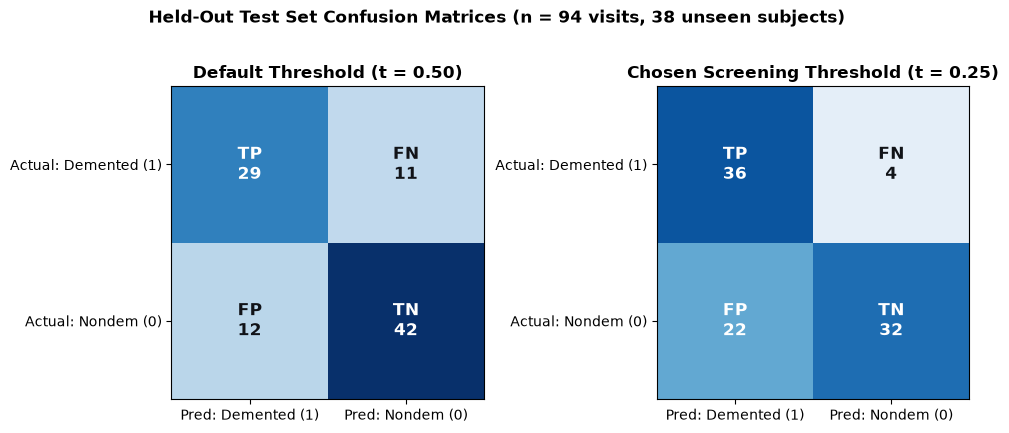

In [14]:
# Plot side-by-side confusion matrices on held-out test set
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, cm, title in [
    (axes[0], cm_default, "Default Threshold (t = 0.50)"),
    (axes[1], cm_screen, "Chosen Screening Threshold (t = 0.25)"),
]:
    im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=max(cm_default.max(), cm_screen.max()))
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(["Pred: Demented (1)", "Pred: Nondem (0)"])
    ax.set_yticklabels(["Actual: Demented (1)", "Actual: Nondem (0)"])
    ax.set_title(title, fontweight="bold")
    cell_labels = [["TP", "FN"], ["FP", "TN"]]
    for i in range(2):
        for j in range(2):
            val = cm[i, j]
            txt_color = "white" if val > cm.max() * 0.55 else "#111318"
            ax.text(j, i, f"{cell_labels[i][j]}\n{val}", ha="center", va="center", color=txt_color, fontsize=12, fontweight="bold")

plt.suptitle("Held-Out Test Set Confusion Matrices (n = 94 visits, 38 unseen subjects)", fontsize=12, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(IMG_DIR, "test_confusion_matrix.png"), dpi=150, bbox_inches="tight")
plt.show()

## 8. Limitations and possible harms

- **Selection & demographic bias:** All participants in OASIS-1 and OASIS-2 are right-handed volunteers from the St. Louis area (many highly educated), and OASIS-2 over-represents demented visits (`44.8%`) compared with community prevalence (`~10%`). Findings may not generalize to left-handed patients, non-US populations, or primary-care settings without recalibration.
- **Heavy reliance on MMSE:** Logistic regression relies strongly on `MMSE`; in a real screening workflow where cognitive testing is unavailable or biased by language/education, performance may drop substantially (to be quantified in Part 4).
- **Alarm fatigue and psychological harm:** At `10%` community prevalence and `t = 0.25`, ~77% of positive flags are false positives. Telling healthy older adults they screened positive for dementia without immediate confirmatory assessment can cause severe anxiety and overburden memory clinics.
- **Not a diagnostic device:** Consistent with course rules, this model is an educational screening/triage prototype and must never be used to diagnose or treat patients.

## 9. Contributions

| Member | GitHub username | Responsibilities | Notebook sections / files | Approx. share of work (Interim Week 10) |
|---|---|---|---|---|
| Fatih Osman Darılmaz | @darilmaz-cmd | Shared Part 1 preparation & subject-wise split foundation; led **Part 5** (10-fold CV comparison, ROC threshold tuning, prevalence analysis, held-out test evaluation), README, and Interim Report | §1–§11, `notebooks/project.ipynb`, `README.md`, `reports/interim_report.pdf` | 100% of completed interim work |
| Yaman Balcı | *(pending)* | Assigned to **Part 4** (MMSE ablation, sex/age subgroup breakdown, feature importance) — planned for final | Planned: Part 4 cells & final report §7.4 | 0% at interim |
| Furkan Selami Düzgün | @furkanduzgun52 | Repository creation (`SE309-Brain-Imaging`); assigned to **Part 1/2/3** coordination — planned for final | Repo setup; planned Part 1/2/3 | Repo setup only |
| Burak Emre Başar | @aLpwren | Assigned to **Part 1/2/3** — planned for final | Planned: Part 1/2/3 | 0% at interim |
| Alperen Keskin | *(pending)* | Assigned to **Part 1/2/3** — planned for final | Planned: Part 1/2/3 | 0% at interim |

**What each member did, in their own words (Interim Week 10):**

- **Fatih Osman Darılmaz:** Accepted the OASIS Data Use Agreement, acquired OASIS-1 and OASIS-2 tabular datasets, implemented the leakage-free subject-wise split and median-imputation pipeline (Part 1 foundation), and executed the full Member 5 screening analysis (10-fold subject-wise CV comparison, ROC curve & threshold `t = 0.25` selection, 44.8% vs 10% prevalence precision analysis, and one-time held-out test evaluation).
- **Furkan Selami Düzgün, Burak Emre Başar, Alperen Keskin, Yaman Balcı:** Have not yet committed code by the Week 10 interim milestone; Yaman Balcı volunteered for Part 4, and Parts 1–3 ownership and individual GitHub commits are scheduled prior to the final submission.

**Interim (Week 10) → Final:** After Week 10, teammates will branch/PR their assigned parts (Part 2 conversion prediction, Part 3 OASIS-1 ↔ OASIS-2 external validation, Part 4 MMSE ablation & subgroup audit) from their own GitHub accounts, expand the final report, and record the 10-minute group presentation video.

## 10. External code, libraries and AI tools

| What | Used for | Where |
|---|---|---|
| `pandas`, `numpy`, `openpyxl` | Loading OASIS Excel files, tabular data cleaning, prevalence arithmetic | §3–§7 |
| `scikit-learn` | Subject-wise splitting (`train_test_split`, `StratifiedGroupKFold`), `Pipeline`, `SimpleImputer`, `StandardScaler`, classifiers, and metrics | §5–§7 |
| `matplotlib` | Exploration histograms, ROC & threshold curves, test confusion matrix plots | §4, §7 |
| `fpdf2` | Generating the Week 10 Interim Report PDF (`reports/interim_report.pdf`) | Report build |
| AI coding assistant (Antigravity / Gemini) | Structuring the notebook template, debugging pipeline/CV code, and drafting report text verified against real outputs | §1–§11, `README.md`, interim report |

## 11. References

1. **OASIS-1 (Cross-Sectional):** Marcus, D. S., Wang, T. H., Parker, J., Csernansky, J. G., Morris, J. C., & Buckner, R. L. (2007). *Open Access Series of Imaging Studies (OASIS): Cross-Sectional MRI Data in Young, Middle Aged, Nondemented, and Demented Older Adults.* Journal of Cognitive Neuroscience, 19(9), 1498–1507. https://doi.org/10.1162/jocn.2007.19.9.1498  
   *Acknowledgments:* Data were provided in part by OASIS-1: Cross-Sectional (Principal Investigators: D. Marcus, R. Buckner, J. Csernansky, J. Morris; P50 AG05681, P01 AG03991, P01 AG026276, R01 AG021910, P20 MH071616, U24 RR021382).
2. **OASIS-2 (Longitudinal):** Marcus, D. S., Fotenos, A. F., Csernansky, J. G., Morris, J. C., & Buckner, R. L. (2010). *Open Access Series of Imaging Studies: Longitudinal MRI Data in Nondemented and Demented Older Adults.* Journal of Cognitive Neuroscience, 22(12), 2677–2684. https://doi.org/10.1162/jocn.2009.21407  
   *Acknowledgments:* Data were provided in part by OASIS-2: Longitudinal (Principal Investigators: D. Marcus, R. Buckner, J. Csernansky, J. Morris; P50 AG05681, P01 AG03991, P01 AG026276, R01 AG021910, P20 MH071616, U24 RR021382).
3. **OASIS Data Access Portal:** https://sites.wustl.edu/oasisbrains/
4. **Course Materials:** SE309 AI and Data Science for Innovation in Health Science (Weeks 1–7 Lectures & Colab Notebooks), Üsküdar University, Dr. Selma Güzel.